# NILM – Semaine 9 : l'IA côté serveur, profils d'usage et recommandations

**La demande d'Éric.** Dans ses retours sur notre présentation, Éric distingue deux approches de l'IA :
1. **en *edge AI*, pour reconnaître le type d'équipement** : c'est le NILM embarqué sur la carte STM32N6, validé en semaine 7 ;
2. **sur le serveur, pour aider à optimiser la consommation en proposant des profils d'usage** : c'est l'objet de ce notebook.

**Ce que reçoit le serveur.** Toutes les 15 minutes, la carte envoie un message de quelques caractères : l'énergie (Wh) consommée par le frigo, la bouilloire, le lave-linge et le lave-vaisselle selon le NILM, et l'énergie totale mesurée de la maison. Le serveur ne voit donc **jamais la courbe brute**, seulement ces résultats. Je reconstitue ici ces messages sur une année complète de la maison UK-DALE, en faisant tourner le réseau retenu en semaine 6 (`ukdale_augoff_s0`).

**Ce que fait l'IA côté serveur**, à partir de l'historique de ces messages :
1. une **carte d'identité du foyer** : consommation par jour et par mois, consommation de veille, part de chaque appareil ;
2. les **habitudes de chaque appareil** : combien de cycles par semaine, à quelle heure, en semaine ou le week-end ;
3. des **profils de journées** appris automatiquement (regroupement *k-means* des journées qui se ressemblent) ;
4. une **prévision de la consommation de demain** à partir de ces profils, qui alimente le planificateur de la semaine 8 ;
5. des **recommandations chiffrées** avec les vrais tarifs : quelle offre choisir sur une année complète, quels appareils décaler et ce que ça rapporte, la consommation de veille, et des alertes (frigo qui dérive, journée anormale).

**Ce que je reprends de la semaine 8.** Les tarifs EDF au 1er août 2026, les couleurs Tempo téléchargées dans `prix/`, et le planificateur du lendemain (programme linéaire et exécution par le boîtier), auquel je donne une meilleure prévision. Le planificateur et l'IA de profils forment ensemble l'*Energy Management System* côté serveur dont parle Éric.

## 1. Réglages
- chemins : données UK-DALE, poids du réseau retenu (`runs_s6/ukdale_augoff_s0/nilm_cnn.pt`), fichier `export_s7/nilm_meta.json` (échelles de puissance utilisées par la carte), dossier `prix/` de la semaine 8 ;
- tarifs : identiques à la semaine 8 (EDF, 1er août 2026, 6 kVA, TTC) ;
- `CYCLE` : pour chaque appareil à cycles, l'énergie minimale par quart d'heure pour le considérer en marche, l'écart toléré entre deux quarts d'heure d'un même cycle (un lave-linge a des phases presque à l'arrêt) et l'énergie minimale d'un cycle complet ;
- `K_PROFILS` : nombre de profils de journées (`None` = choisi automatiquement) ;
- `CHAUFFE_EAU_KWH` : pour la comparaison des offres, j'ajoute un chauffe-eau électrique sur contacteur heures creuses (5 kWh par jour), car la maison UK-DALE chauffe son eau au gaz alors qu'un foyer français type a un cumulus.

In [1]:
from pathlib import Path
import json, math, ssl, urllib.request, pickle, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog

# ================== CHEMINS ==================
DATA_DIR = Path.home() / "Desktop/MASTER/Projet/Modele_IA/house_1/an1"
RUN_DIR = Path("runs_s6/ukdale_augoff_s0")            # le réseau embarqué sur la carte (semaines 6 et 7)
META = Path("export_s7/nilm_meta.json")               # échelles utilisées par la carte
PRIX_DIR = Path("prix"); PRIX_DIR.mkdir(exist_ok=True)   # prix téléchargés en semaine 8
OUT_DIR = Path("profils_s9"); OUT_DIR.mkdir(exist_ok=True)
# ================== DONNÉES (identiques aux semaines 3 à 8) ==================
MAINS = "aggregate"
APPS = ["fridge", "kettle", "washing_machine", "dishwasher"]
NOMS = {"fridge": "frigo", "kettle": "bouilloire", "washing_machine": "lave-linge", "dishwasher": "lave-vaisselle"}
LOAD = ("2013-03-01", "2014-02-28")
TEST_FRAC = 0.30
DILS = (1, 2, 4, 8, 16, 32, 64)
# ================== DÉTECTION DES CYCLES (sur les messages de 15 min) ==================
CYCLE = {"washing_machine": {"seuil_wh": 25, "trou": 2, "min_wh": 200},
         "dishwasher":      {"seuil_wh": 25, "trou": 2, "min_wh": 300},
         "kettle":          {"seuil_wh": 30, "trou": 0, "min_wh": 30}}
K_PROFILS = None                                      # None = choix automatique (silhouette), sinon un entier
# ================== TARIFS (semaine 8) ==================
BASE = 0.2001
HPHC = {"HP": 0.2142, "HC": 0.1589}
HC_HOURS = [22, 23, 0, 1, 2, 3, 4, 5]
TEMPO = {"BLEU": (0.1356, 0.1654), "BLANC": (0.1536, 0.1921), "ROUGE": (0.1615, 0.7295)}
ABONNEMENT = {"Base": 190.32, "HP/HC": 190.32, "Tempo": 189.60}
CHAUFFE_EAU_KWH = 5.0                                 # cumulus simulé sur contacteur HC (0 pour l'enlever)
HEURE_CONSEIL = 22                                    # heure de départ conseillée en HP/HC et Tempo (début des heures creuses)
# ================== PLANIFICATEUR (semaine 8) ==================
WH_CAP, WH_P, WH_DAY, WH_LOSS, WH_MIN = 7.0, 2.0, 5.0, 0.01, 1.0
DRAW = np.zeros(24)
for h_, w_ in {6: .10, 7: .20, 8: .10, 12: .05, 13: .05, 18: .10, 19: .15, 20: .10, 21: .10, 22: .05}.items():
    DRAW[h_] = w_ * WH_DAY
BAT_CAP, BAT_P, BAT_ETA, BAT_SOC_MIN, BAT_START = 5.0, 2.5, 0.95, 0.5, 2.5
DYN_HORS_ENERGIE, TVA = 0.085, 1.20
plt.rcParams["figure.figsize"] = (11, 3.2); plt.rcParams["axes.grid"] = True
print("DATA_DIR :", "OK" if (DATA_DIR / "labels.dat").exists() else "INTROUVABLE",
      "| poids :", "OK" if (RUN_DIR / "nilm_cnn.pt").exists() else "INTROUVABLE",
      "| prix S8 :", sorted(p.name for p in PRIX_DIR.glob("*.csv")))

DATA_DIR : OK | poids : OK | prix S8 : ['spot_FR_2024-11-11_2025-03-02.csv', 'tempo_2023-2024.csv', 'tempo_2024-2025.csv']


## 2. Reconstituer les messages reçus par le serveur
Je relis l'année UK-DALE (comme en semaine 6), puis je fais passer **toute l'année** dans le réseau NILM retenu. Les calculs du réseau sont refaits ici avec `numpy` (convolutions dilatées), à partir des poids de la semaine 6 : ce sont exactement les mêmes opérations que sur la carte, en virgule flottante. La sortie est convertie comme sur la carte : puissance = max(sortie, 0) × échelle, mise à 0 si le score « allumé » est négatif.

Je regroupe ensuite par **quart d'heure**, comme les messages NB-IoT : énergie de chaque appareil selon le NILM, et énergie totale **mesurée** (le capteur de courant). Un quart d'heure n'est gardé que s'il contient au moins 12 minutes valides. Pour comparer, je construis aussi les mêmes messages avec la **vraie** consommation des appareils (prises de mesure d'UK-DALE), que le serveur n'aura jamais en vrai.

Les heures sont passées en **heure locale britannique** (heure d'été comprise), car les habitudes des habitants suivent l'heure de leur horloge.

**Attention** : de mars à mi-novembre 2013, le NILM a été entraîné sur ces mêmes données ; ses estimations y sont donc un peu trop bonnes. Les comparaisons NILM / réel sont faites sur la **période de test** (12 novembre 2013 – 28 février 2014), jamais vue par le réseau.

In [2]:
def read_labels(folder):
    labels = {}
    for line in (folder / "labels.dat").read_text().splitlines():
        p = line.split(maxsplit=1)
        if len(p) == 2:
            labels[p[1].strip()] = int(p[0])
    return labels

def read_channel(folder, ch):
    df = pd.read_csv(folder / f"channel_{ch}.dat", sep=r"\s+", header=None, usecols=[0, 1], names=["t", "w"])
    df.index = pd.to_datetime(df["t"], unit="s")
    s = df["w"].astype(float)
    return s[~s.index.duplicated()].sort_index().loc[LOAD[0]:LOAD[1]]

labels = read_labels(DATA_DIR)
series = {n: read_channel(DATA_DIR, labels[n]).resample("1min").mean() for n in [MAINS] + APPS}
data = pd.DataFrame(series)
data = data.loc[:min(s.index.max() for s in series.values())]
data = data.reindex(pd.date_range(data.index.min(), data.index.max(), freq="1min"))
valid = data.notna().all(axis=1).values
T = len(data); i_test = int(T * (1 - TEST_FRAC))
DEBUT_TEST = data.index[i_test].normalize() + pd.Timedelta(days=1)

# ---------- poids du réseau (torch si disponible, sinon lecture directe du fichier .pt) ----------
def charger_poids(path):
    try:
        import torch
        return {k: v.cpu().numpy().astype(np.float32) for k, v in torch.load(path, map_location="cpu").items()}
    except ImportError:
        z = zipfile.ZipFile(path); root = z.namelist()[0].split("/")[0]
        class Lecteur(pickle.Unpickler):
            def find_class(self, mod, name):
                if name == "_rebuild_tensor_v2":
                    return lambda st, off, size, stride, *a: np.lib.stride_tricks.as_strided(
                        st[off:], shape=size, strides=[s * 4 for s in stride]).copy()
                if name == "FloatStorage": return "f32"
                if name == "OrderedDict":
                    import collections; return collections.OrderedDict
                return super().find_class(mod, name)
            def persistent_load(self, pid):
                return np.frombuffer(z.read(f"{root}/data/{pid[2]}"), dtype="<f4")
        return Lecteur(z.open(f"{root}/data.pkl")).load()

def conv1d(x, w, b, d=1):
    k = w.shape[2]; pad = d * (k - 1) // 2; L = x.shape[1]
    xp = np.pad(x, ((0, 0), (pad, pad)))
    out = np.repeat(b[:, None], L, axis=1).astype(np.float32)
    for j in range(k):
        out += w[:, :, j] @ xp[:, j * d: j * d + L]
    return out

def reseau(X, W):
    h = np.maximum(conv1d(X, W["inp.weight"], W["inp.bias"]), 0)
    for i, d in enumerate(DILS):
        h += np.maximum(conv1d(h, W[f"blocks.{i}.weight"], W[f"blocks.{i}.bias"], d), 0)
    return conv1d(h, W["out.weight"], W["out.bias"])

W = charger_poids(RUN_DIR / "nilm_cnn.pt")
echelles = np.array(json.loads(META.read_text())["sortie"]["echelles_W"], np.float32) if META.exists() else None
agg = data[MAINS].fillna(0).values.astype(np.float32)
heure = (data.index.hour + data.index.minute / 60).values
X = np.vstack([agg / 1000.0, np.sin(2 * np.pi * heure / 24), np.cos(2 * np.pi * heure / 24)]).astype(np.float32)
X[:, ~valid] = 0.0
out = reseau(X, W)
pred = np.maximum(out[:4], 0) * echelles[:, None] * (out[4:] > 0)
print(f"NILM appliqué à {T} minutes ({W['inp.weight'].shape[0]} canaux internes) | échelles (W) : {echelles.round(1)}")

# ---------- messages de 15 min (Wh), en heure locale britannique ----------
def quarts(df_w):
    g = df_w.resample("15min")
    wh = g.mean() / 4.0                                   # puissance moyenne (W) × 0,25 h
    wh[g.count() < 12] = np.nan
    loc = wh.index.tz_localize("UTC").tz_convert("Europe/London").tz_localize(None)
    return wh.set_axis(loc)

masque = pd.Series(valid, index=data.index)
tot = data[[MAINS]].where(masque, np.nan).rename(columns={MAINS: "total"})
msg_nilm = quarts(pd.concat([tot, pd.DataFrame(pred.T, index=data.index, columns=APPS).where(masque, np.nan)], axis=1))
msg_reel = quarts(pd.concat([tot, data[APPS].where(masque, np.nan)], axis=1))
msg_nilm.round(1).to_csv(OUT_DIR / "messages_15min_nilm.csv")
test = msg_nilm.index >= DEBUT_TEST
print(f"{len(msg_nilm)} messages de 15 min ({msg_nilm['total'].notna().mean():.1%} complets), test à partir du {DEBUT_TEST.date()}")

# qualité des messages sur la période de test : le NILM comparé à la réalité
q = []
for a in APPS:
    n_, r_ = msg_nilm.loc[test, a], msg_reel.loc[test, a]
    ok = n_.notna() & r_.notna()
    jn, jr = n_[ok].groupby(n_[ok].index.date).sum(), r_[ok].groupby(r_[ok].index.date).sum()
    q.append({"appareil": NOMS[a], "énergie réelle (kWh)": r_[ok].sum() / 1000, "énergie NILM (kWh)": n_[ok].sum() / 1000,
              "erreur énergie (%)": 100 * (n_[ok].sum() - r_[ok].sum()) / r_[ok].sum(),
              "erreur moyenne par quart d'heure (Wh)": (n_[ok] - r_[ok]).abs().mean(),
              "erreur moyenne par jour (Wh)": (jn - jr).abs().mean()})
qualite = pd.DataFrame(q).set_index("appareil")
qualite.round(1)

NILM appliqué à 525600 minutes (32 canaux internes) | échelles (W) : [ 249.7 2405.5 1975.3 2392.1]
35040 messages de 15 min (94.6% complets), test à partir du 2013-11-12


,énergie réelle (kWh),énergie NILM (kWh),erreur énergie (%),erreur moyenne par quart d'heure (Wh),erreur moyenne par jour (Wh)
appareil,,,,,
frigo,97.2,113.000000,16.3,4.5,155.5
bouilloire,36.9,46.099998,25.0,1.9,102.5
lave-linge,82.1,83.099998,1.2,2.3,117.5
lave-vaisselle,44.5,51.000000,14.6,1.6,95.2


## 3. La carte d'identité du foyer
Premier service rendu par le serveur : résumer la consommation du foyer en quelques chiffres et graphiques, comme le ferait le tableau Énergie de Home Assistant, mais avec le détail par appareil apporté par le NILM :
- consommation moyenne par jour, en semaine et le week-end, et son évolution mois par mois ;
- **consommation de veille** (le « talon ») : la puissance la plus basse de chaque nuit (entre 1 h et 5 h), c'est-à-dire ce qui reste allumé en permanence (box, appareils en veille, frigo au repos…) ;
- part de chaque appareil suivi dans la consommation, le reste étant « autres usages » ;
- profil moyen de la journée, en semaine et le week-end.

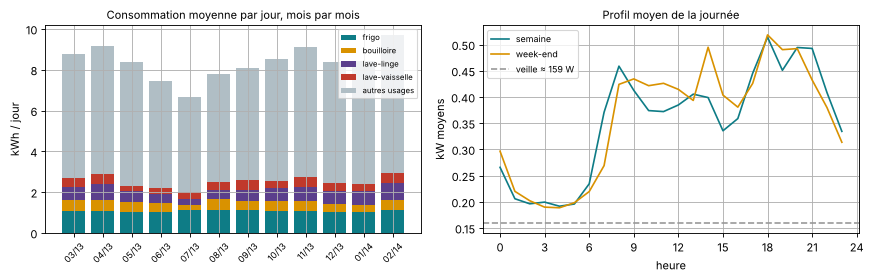

jours analysés                                 334.0
consommation moyenne (kWh/jour)                  8.3
en semaine (kWh/jour)                            8.3
le week-end (kWh/jour)                           8.4
consommation de veille (W)                     158.7
veille sur un an (kWh)                        1390.0
veille sur un an (€, tarif Base)               278.1
part de la veille dans la consommation (%)      45.7
part du frigo (%)                               12.9
part de la bouilloire (%)                        5.4
part du lave-linge (%)                           7.3
part du lave-vaisselle (%)                       4.8
part des autres usages (%)                      69.7
dtype: float64

In [3]:
jour = msg_nilm.index.normalize()
journalier = msg_nilm.groupby(jour).sum(min_count=80) / 1000          # kWh par jour (au moins 80 quarts d'heure sur 96)
journalier = journalier.dropna(subset=["total"])
we = journalier.index.dayofweek >= 5
nuit = msg_nilm["total"][(msg_nilm.index.hour >= 1) & (msg_nilm.index.hour < 5)] * 4     # W moyens sur le quart d'heure
talon_j = nuit.groupby(nuit.index.normalize()).min()
TALON_W = float(talon_j.median())
parts = (journalier[APPS].sum() / journalier["total"].sum() * 100).rename(index=NOMS)
identite = {
    "jours analysés": len(journalier),
    "consommation moyenne (kWh/jour)": journalier["total"].mean(),
    "en semaine (kWh/jour)": journalier.loc[~we, "total"].mean(),
    "le week-end (kWh/jour)": journalier.loc[we, "total"].mean(),
    "consommation de veille (W)": TALON_W,
    "veille sur un an (kWh)": TALON_W * 8.76,
    "veille sur un an (€, tarif Base)": TALON_W * 8.76 * BASE,
    "part de la veille dans la consommation (%)": 100 * TALON_W * 24 / 1000 / journalier["total"].mean(),
}
for k_, v_ in parts.items():
    identite[f"part du {k_} (%)" if k_ in ("frigo", "lave-linge", "lave-vaisselle") else f"part de la {k_} (%)"] = v_
identite["part des autres usages (%)"] = 100 - parts.sum()
identite = pd.Series(identite)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
mens = journalier.groupby(journalier.index.to_period("M")).mean()
autres = mens["total"] - mens[APPS].sum(axis=1)
bas = np.zeros(len(mens)); cols = {"fridge": "#0E7C86", "kettle": "#D99200", "washing_machine": "#5B3F8C", "dishwasher": "#C0392B"}
for a in APPS:
    axes[0].bar(range(len(mens)), mens[a], bottom=bas, color=cols[a], label=NOMS[a]); bas += mens[a].values
axes[0].bar(range(len(mens)), autres, bottom=bas, color="#B0BEC5", label="autres usages")
axes[0].set_xticks(range(len(mens))); axes[0].set_xticklabels([p.strftime("%m/%y") for p in mens.index], fontsize=8, rotation=45)
axes[0].set_ylabel("kWh / jour"); axes[0].set_title("Consommation moyenne par jour, mois par mois", fontsize=10); axes[0].legend(fontsize=7)
prof = msg_nilm["total"].groupby([msg_nilm.index.dayofweek >= 5, msg_nilm.index.hour]).mean() * 4 / 1000
axes[1].plot(range(24), prof.loc[False].values, label="semaine", color="#0E7C86")
axes[1].plot(range(24), prof.loc[True].values, label="week-end", color="#D99200")
axes[1].axhline(TALON_W / 1000, color="#999", ls="--", label=f"veille ≈ {TALON_W:.0f} W")
axes[1].set_xticks(range(0, 25, 3)); axes[1].set_xlabel("heure"); axes[1].set_ylabel("kW moyens")
axes[1].set_title("Profil moyen de la journée", fontsize=10); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "identite_foyer.png", dpi=130); plt.show()
identite.round(1)

## 4. Les habitudes de chaque appareil
À partir des messages, je retrouve les **cycles** du lave-linge, du lave-vaisselle et de la bouilloire : une suite de quarts d'heure où l'énergie dépasse un seuil, en tolérant de courtes pauses à l'intérieur d'un cycle (rinçage, séchage). Pour chaque cycle : son heure de début, sa durée et son énergie. J'en tire, pour chaque appareil, le nombre de cycles par semaine, l'énergie d'un cycle et surtout **les heures de départ habituelles**, en semaine et le week-end : c'est ce qui permet de proposer un décalage adapté à chaque foyer.

Pour vérifier que le serveur peut se fier au NILM, je compare sur la période de test les habitudes trouvées à partir des messages NILM et à partir des vraies mesures.

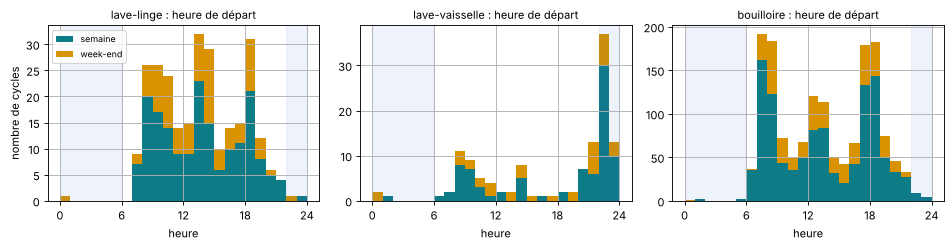

,cycles par semaine,énergie d'un cycle (kWh),durée moyenne (min),heure de départ la plus fréquente,part des départs le week-end (%),part des départs en heures pleines (%),cycles/semaine en test (NILM),heure moyenne de départ en test (NILM),cycles/semaine en test (réel),heure moyenne de départ en test (réel)
appareil,,,,,,,,,,
lave-linge,5.19,0.76,92.94,14,33.33,98.89,5.38,14.17,5.06,14.04
lave-vaisselle,2.38,1.13,104.27,22,30.65,57.26,2.59,17.34,2.20,16.96
bouilloire,29.44,0.10,18.73,8,27.17,98.76,29.17,13.68,25.02,13.43


In [4]:
def cycles(s, seuil_wh, trou, min_wh):
    v = s.fillna(0).values; t = s.index; res = []; i = 0; n = len(v)
    while i < n:
        if v[i] <= seuil_wh: i += 1; continue
        j, fin = i, i
        while j < n and (v[j] > seuil_wh or (j - fin) <= trou):
            if v[j] > seuil_wh: fin = j
            j += 1
        e = v[i:fin + 1].sum()
        if e >= min_wh:
            res.append({"debut": t[i], "duree_min": 15 * (fin - i + 1), "energie_wh": e})
        i = fin + 1
    return pd.DataFrame(res)

CYC = {src: {a: cycles(m[a], **CYCLE[a]) for a in CYCLE} for src, m in (("NILM", msg_nilm), ("réel", msg_reel))}
semaines_tot = (msg_nilm.index[-1] - msg_nilm.index[0]).days / 7
semaines_test = (msg_nilm.index[-1] - DEBUT_TEST).days / 7
rows = []
for a in CYCLE:
    c = CYC["NILM"][a]; h = c["debut"].dt.hour + c["debut"].dt.minute / 60
    w_ = c["debut"].dt.dayofweek >= 5
    hp = ~c["debut"].dt.hour.isin(HC_HOURS)
    row = {"appareil": NOMS[a], "cycles par semaine": len(c) / semaines_tot, "énergie d'un cycle (kWh)": c["energie_wh"].mean() / 1000,
           "durée moyenne (min)": c["duree_min"].mean(), "heure de départ la plus fréquente": int(h.round().mode()[0]) if len(c) else None,
           "part des départs le week-end (%)": 100 * w_.mean(), "part des départs en heures pleines (%)": 100 * hp.mean()}
    for src in ("NILM", "réel"):
        ct = CYC[src][a]; ct = ct[ct["debut"] >= DEBUT_TEST]
        row[f"cycles/semaine en test ({src})"] = len(ct) / semaines_test
        row[f"heure moyenne de départ en test ({src})"] = (ct["debut"].dt.hour + ct["debut"].dt.minute / 60).mean()
    rows.append(row)
habitudes = pd.DataFrame(rows).set_index("appareil")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=False)
for ax, a in zip(axes, CYCLE):
    c = CYC["NILM"][a]; w_ = c["debut"].dt.dayofweek >= 5
    ax.hist([c.loc[~w_, "debut"].dt.hour, c.loc[w_, "debut"].dt.hour], bins=np.arange(25), stacked=True,
            color=["#0E7C86", "#D99200"], label=["semaine", "week-end"])
    ax.axvspan(22, 24, color="#2E6FD8", alpha=0.08); ax.axvspan(0, 6, color="#2E6FD8", alpha=0.08)
    ax.set_title(f"{NOMS[a]} : heure de départ", fontsize=10); ax.set_xticks(range(0, 25, 6)); ax.set_xlabel("heure")
axes[0].set_ylabel("nombre de cycles"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "habitudes.png", dpi=130); plt.show()
habitudes.round(2)

## 5. Les profils de journées
Chaque journée est résumée par sa **forme** : la part de sa consommation qui tombe à chaque heure (24 valeurs dont la somme vaut 1). Je regroupe les journées qui se ressemblent avec l'algorithme **k-means** (écrit ici en quelques lignes avec `numpy`) : chaque groupe est un **profil d'usage**, et son centre est la journée type de ce profil. Le nombre de profils est choisi automatiquement avec le **score de silhouette** (plus il est haut, mieux les groupes sont séparés).

Pour rester honnête vis-à-vis de la prévision (section 6), les profils sont **appris uniquement sur les journées avant la période de test** ; chaque journée de test est ensuite rangée dans le profil dont elle est la plus proche, une fois qu'elle est passée.

Le tableau décrit chaque profil : nombre de jours, part de week-end, consommation moyenne, heure de pointe, et part des jours avec une lessive ou une vaisselle.

score de silhouette : {2: 0.113, 3: 0.124, 4: 0.129, 5: 0.14, 6: 0.106} -> nombre de profils retenu : 5


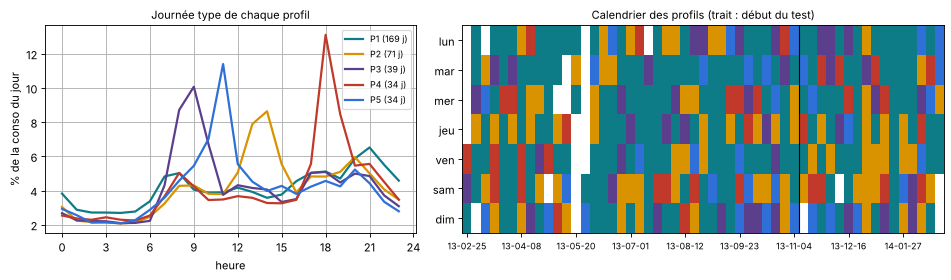

,jours,part de week-end (%),kWh par jour,heure de pointe,part de la conso avant 12 h (%),part de la conso de 17 h à 23 h (%),jours avec lessive (%),jours avec vaisselle (%),mois le plus fréquent
profil,,,,,,,,,
P1,169,20.7,7.5,21,42.7,32.8,25.4,28.4,7
P2,71,35.2,9.7,14,35.7,29.8,88.7,36.6,1
P3,39,30.8,9.4,9,49.4,28.2,84.6,56.4,10
P4,34,35.3,9.2,18,36.6,42.7,91.2,20.6,3
P5,34,41.2,9.7,11,49.0,26.1,88.2,47.1,2


In [5]:
horaire = msg_nilm["total"].groupby([msg_nilm.index.normalize(), msg_nilm.index.hour]).mean() * 4 / 1000   # kWh par heure
H = horaire.unstack().reindex(columns=range(24))
H = H[H.notna().sum(axis=1) >= 20].interpolate(axis=1, limit_direction="both")
FORME = H.div(H.sum(axis=1), axis=0)
appr = FORME.index < DEBUT_TEST

def kmeans(Xk, k, n_init=10, iters=200, seed=0):
    rng = np.random.default_rng(seed); meilleur = None
    for _ in range(n_init):
        C = [Xk[rng.integers(len(Xk))]]
        for _ in range(1, k):
            d2 = np.min(((Xk[:, None, :] - np.array(C)[None]) ** 2).sum(-1), 1)
            C.append(Xk[rng.choice(len(Xk), p=d2 / d2.sum())])
        C = np.array(C)
        for _ in range(iters):
            lab = ((Xk[:, None, :] - C[None]) ** 2).sum(-1).argmin(1)
            C2 = np.array([Xk[lab == j].mean(0) if (lab == j).any() else C[j] for j in range(k)])
            if np.allclose(C2, C): break
            C = C2
        inertie = ((Xk - C[lab]) ** 2).sum()
        if meilleur is None or inertie < meilleur[0]: meilleur = (inertie, C, lab)
    return meilleur[1], meilleur[2]

def silhouette(Xk, lab):
    D = np.sqrt(((Xk[:, None] - Xk[None]) ** 2).sum(-1)); s = []
    for i in range(len(Xk)):
        m = lab == lab[i]
        if m.sum() <= 1: s.append(0.0); continue
        a_ = D[i, m].sum() / (m.sum() - 1)
        b_ = min(D[i, lab == j].mean() for j in np.unique(lab) if j != lab[i])
        s.append((b_ - a_) / max(a_, b_))
    return float(np.mean(s))

Xa = FORME[appr].values
scores = {k: silhouette(Xa, kmeans(Xa, k)[1]) for k in range(2, 7)}
K = K_PROFILS or max(scores, key=scores.get)
C, lab_a = kmeans(Xa, K)
ordre = np.argsort([-(lab_a == j).sum() for j in range(K)])            # profil 1 = le plus fréquent
C = C[ordre]
LAB = pd.Series(((FORME.values[:, None, :] - C[None]) ** 2).sum(-1).argmin(1), index=FORME.index)
print("score de silhouette :", {k: round(v, 3) for k, v in scores.items()}, "-> nombre de profils retenu :", K)

jours_ll = set(CYC["NILM"]["washing_machine"]["debut"].dt.normalize())
jours_lv = set(CYC["NILM"]["dishwasher"]["debut"].dt.normalize())
desc = []
for j in range(K):
    d_ = LAB.index[LAB == j]
    desc.append({"profil": f"P{j + 1}", "jours": len(d_), "part de week-end (%)": 100 * np.mean(d_.dayofweek >= 5),
                 "kWh par jour": H.loc[d_].sum(axis=1).mean(), "heure de pointe": int(C[j].argmax()),
                 "part de la conso avant 12 h (%)": 100 * C[j][:12].sum(), "part de la conso de 17 h à 23 h (%)": 100 * C[j][17:23].sum(),
                 "jours avec lessive (%)": 100 * np.mean([x in jours_ll for x in d_]),
                 "jours avec vaisselle (%)": 100 * np.mean([x in jours_lv for x in d_]),
                 "mois le plus fréquent": pd.Series(d_.month).mode()[0]})
profils = pd.DataFrame(desc).set_index("profil")
profils.round(1).to_csv(OUT_DIR / "profils_journees.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
couleurs_p = ["#0E7C86", "#D99200", "#5B3F8C", "#C0392B", "#2E6FD8", "#78909C"]
for j in range(K):
    axes[0].plot(range(24), C[j] * 100, color=couleurs_p[j], lw=2, label=f"P{j + 1} ({(LAB == j).sum()} j)")
axes[0].set_xticks(range(0, 25, 3)); axes[0].set_xlabel("heure"); axes[0].set_ylabel("% de la conso du jour")
axes[0].set_title("Journée type de chaque profil", fontsize=10); axes[0].legend(fontsize=8)
sem = pd.DataFrame({"lab": LAB, "sem": LAB.index.to_period("W"), "dow": LAB.index.dayofweek})
grille = sem.pivot_table(index="dow", columns="sem", values="lab", aggfunc="first")
from matplotlib.colors import ListedColormap
axes[1].imshow(grille.values, aspect="auto", cmap=ListedColormap(couleurs_p[:K]), vmin=-0.5, vmax=K - 0.5, interpolation="none")
axes[1].set_yticks(range(7)); axes[1].set_yticklabels(["lun", "mar", "mer", "jeu", "ven", "sam", "dim"])
xt = list(range(0, grille.shape[1], 6)); axes[1].set_xticks(xt); axes[1].set_xticklabels([str(grille.columns[i].start_time.date())[2:] for i in xt], fontsize=8)
axes[1].axvline(list(grille.columns).index(pd.Timestamp(DEBUT_TEST).to_period("W")) - 0.5, color="k", lw=1)
axes[1].set_title("Calendrier des profils (trait : début du test)", fontsize=10); axes[1].grid(False)
plt.tight_layout(); plt.savefig(OUT_DIR / "profils.png", dpi=130); plt.show()
profils.round(1)

## 6. Prévoir la consommation de demain
Le planificateur de la semaine 8 a besoin d'une prévision de la consommation de la maison heure par heure pour le lendemain (pour savoir quand la batterie peut se décharger utilement). J'y avais mis la méthode la plus simple : la moyenne des 7 derniers jours. Je compare ici, sur chaque jour de la période de test, plusieurs prévisions qui n'utilisent que le passé :
1. **moyenne des 7 derniers jours** (semaine 8) ;
2. **même jour de la semaine précédente** ;
3. **moyenne des 4 derniers mêmes jours de la semaine** (les 4 derniers mardis pour un mardi) ;
4. **profil d'usage** : le profil le plus fréquent ces 4 dernières semaines pour ce jour de la semaine, mis à l'échelle de la consommation des 7 derniers jours ;
5. **profil d'usage + niveau du même jour** : la même forme, mise à l'échelle de la consommation moyenne des 4 derniers mêmes jours de la semaine.

Je mesure l'erreur moyenne heure par heure (kWh) et l'erreur sur l'énergie du jour.

In [6]:
HJ = H.copy()
jours_test = [d for d in HJ.index if d >= DEBUT_TEST]
def prev(d, methode):
    passe = HJ[HJ.index < d]
    memes = passe[passe.index.dayofweek == d.dayofweek].tail(4)
    if methode == "1. moyenne 7 jours": return passe.tail(7).mean().values
    if methode == "2. même jour, semaine d'avant": return memes.iloc[-1].values
    if methode == "3. moyenne des 4 mêmes jours": return memes.mean().values
    p = LAB.reindex(memes.index).dropna().astype(int).mode()[0]
    niveau = passe.tail(7).sum(axis=1).mean() if methode.startswith("4") else memes.sum(axis=1).mean()
    return C[p] * niveau
METHODES = ["1. moyenne 7 jours", "2. même jour, semaine d'avant", "3. moyenne des 4 mêmes jours",
            "4. profil d'usage", "5. profil d'usage + niveau du même jour"]
PREV = {m: np.stack([prev(d, m) for d in jours_test]) for m in METHODES}
REEL = HJ.loc[jours_test].values
eval_prev = pd.DataFrame({m: {"erreur moyenne par heure (kWh)": np.abs(P_ - REEL).mean(),
                              "erreur sur l'énergie du jour (%)": 100 * np.mean(np.abs(P_.sum(1) - REEL.sum(1)) / REEL.sum(1))}
                          for m, P_ in PREV.items()}).T
MEILLEURE = eval_prev["erreur moyenne par heure (kWh)"].idxmin()
print(f"{len(jours_test)} jours de test | meilleure prévision : {MEILLEURE}")
eval_prev.round(3)

107 jours de test | meilleure prévision : 1. moyenne 7 jours


,erreur moyenne par heure (kWh),erreur sur l'énergie du jour (%)
1. moyenne 7 jours,0.169,29.434
"2. même jour, semaine d'avant",0.223,42.272
3. moyenne des 4 mêmes jours,0.174,31.411
4. profil d'usage,0.171,29.434
5. profil d'usage + niveau du même jour,0.171,31.411


### La prévision branchée sur le planificateur de la semaine 8
Je reprends le planificateur du lendemain de la semaine 8 (programme linéaire sur la journée, consignes tout-ou-rien exécutées par le boîtier avec la vraie consommation) et je compare le coût obtenu avec plusieurs prévisions : la moyenne des 7 jours (semaine 8), le profil d'usage (et la meilleure prévision ci-dessus si c'en est une autre), et une prévision **parfaite** (la vraie consommation, impossible en pratique) qui montre le maximum que l'on peut gagner en prévoyant mieux. Les prix sont ceux de la semaine 8 (Tempo et spot de l'hiver 2024-2025, dans `prix/`), alignés de la même façon (même jour de la semaine).

In [7]:
def optimise_day(price, base_d, e0, s0):
    n = 24; nv = 5 * n
    ih, ic, idd, ie, isoc = (slice(k * n, (k + 1) * n) for k in range(5))
    cost = np.concatenate([price, price, -price, np.zeros(n), np.zeros(n)])
    cost[ie.start + n - 1] = -0.95 * price.min(); cost[isoc.start + n - 1] = -BAT_ETA * price.min()
    Aeq = np.zeros((2 * n, nv)); beq = np.zeros(2 * n)
    for t in range(n):
        Aeq[t, ie.start + t] = 1; Aeq[t, ih.start + t] = -1
        if t > 0: Aeq[t, ie.start + t - 1] = -(1 - WH_LOSS)
        beq[t] = -DRAW[t] + ((1 - WH_LOSS) * e0 if t == 0 else 0)
        Aeq[n + t, isoc.start + t] = 1; Aeq[n + t, ic.start + t] = -BAT_ETA; Aeq[n + t, idd.start + t] = 1 / BAT_ETA
        if t > 0: Aeq[n + t, isoc.start + t - 1] = -1
        beq[n + t] = s0 if t == 0 else 0
    Aub = np.zeros((n, nv)); bub = np.asarray(base_d, float)
    for t in range(n):
        Aub[t, idd.start + t] = 1; Aub[t, ih.start + t] = -1
    b = [(0, WH_P)] * n + [(0, BAT_P)] * (2 * n) + [(WH_MIN, WH_CAP)] * n + [(BAT_SOC_MIN, BAT_CAP)] * n
    r = linprog(cost, A_ub=Aub, b_ub=bub, A_eq=Aeq, b_eq=beq, bounds=b, method="highs")
    return None if r.status != 0 else (r.x[ih], r.x[ic], r.x[idd])

def executer_jour(autor, modes, base_d, e0, s0):
    e, s, G = e0, s0, np.zeros(24)
    for t in range(24):
        e_pre = max(e * (1 - WH_LOSS) - DRAW[t], 0.0)
        h = min(WH_P, max(0.0, WH_CAP - e_pre)) if autor[t] else 0.0
        e = e_pre + h
        c = min(BAT_P, max(0.0, (BAT_CAP - s) / BAT_ETA)) if modes[t] == 1 else 0.0
        d = min(BAT_P, max(0.0, (s - BAT_SOC_MIN) * BAT_ETA), base_d[t] + h) if modes[t] == 2 else 0.0
        s += BAT_ETA * c - d / BAT_ETA; G[t] = base_d[t] + h + c - d
    return G, e, s

def charger_tempo_fichier(saison):
    f = PRIX_DIR / f"tempo_{saison}.csv"
    return pd.read_csv(f, parse_dates=["date"]).set_index("date")["couleur"] if f.exists() else None

def decalage(d0):                                     # même jour de la semaine, saison 2024-2025 (comme en semaine 8)
    cible = pd.Timestamp(year=2024, month=d0.month, day=d0.day) if d0.month >= 3 else pd.Timestamp(year=2025, month=d0.month, day=min(d0.day, 28))
    return int(round((cible - d0).days / 7) * 7)
OFF = decalage(pd.Timestamp(jours_test[0]))
tempo_s8 = charger_tempo_fichier("2024-2025")
spot_f = sorted(PRIX_DIR.glob("spot_FR_*.csv"))
spot_s8 = pd.read_csv(spot_f[0], parse_dates=["time"]).set_index("time")["eur_mwh"] if spot_f else None

def prix_tempo(j, tempo):
    cv, cj = tempo.get(j - pd.Timedelta(days=1), "BLEU"), tempo.get(j, "BLEU")
    return np.array([TEMPO[cv][0] if h < 6 else (TEMPO[cj][0] if h >= 22 else TEMPO[cj][1]) for h in range(24)])

PRIX_TEST = {}
if tempo_s8 is not None:
    PRIX_TEST["Tempo"] = np.stack([prix_tempo(pd.Timestamp(d) + pd.Timedelta(days=OFF), tempo_s8) for d in jours_test])
if spot_s8 is not None:
    sp = spot_s8.groupby(spot_s8.index).mean()
    PRIX_TEST["Dynamique"] = np.stack([TVA * (sp.reindex(pd.date_range(pd.Timestamp(d) + pd.Timedelta(days=OFF), periods=24, freq="1h"))
                                             .interpolate(limit_direction="both").values / 1000 + DYN_HORS_ENERGIE) for d in jours_test])
rows = []
for tarif, PX in PRIX_TEST.items():
    choix = [("moyenne 7 jours (semaine 8)", PREV["1. moyenne 7 jours"]), ("profil d'usage", PREV["4. profil d'usage"]), ("prévision parfaite", REEL)]
    if MEILLEURE not in ("1. moyenne 7 jours", "4. profil d'usage"):
        choix.insert(2, (f"meilleure : {MEILLEURE}", PREV[MEILLEURE]))
    for nom, P_ in choix:
        e, s, cout = WH_CAP, BAT_START, 0.0
        for k in range(len(jours_test)):
            r = optimise_day(PX[k], np.clip(P_[k], 0, None), e, s)
            autor, modes = (r[0] > 1e-6, np.where(r[1] > 0.05, 1, np.where(r[2] > 0.05, 2, 0))) if r else (np.isin(range(24), HC_HOURS), np.zeros(24, int))
            G, e, s = executer_jour(autor, modes, REEL[k], e, s)
            cout += (G * PX[k]).sum()
        rows.append({"tarif": tarif, "prévision": nom, "coût (€)": cout, "€/jour": cout / len(jours_test)})
plan_prev = pd.DataFrame(rows).set_index(["tarif", "prévision"]) if rows else pd.DataFrame()
if len(plan_prev):
    for t in PRIX_TEST:
        ref = plan_prev.loc[(t, "moyenne 7 jours (semaine 8)"), "coût (€)"]
        for p_ in plan_prev.loc[t].index:
            plan_prev.loc[(t, p_), "gain vs semaine 8 (€)"] = ref - plan_prev.loc[(t, p_), "coût (€)"]
else:
    print("Pas de prix de la semaine 8 dans prix/ : lancer d'abord le notebook de la semaine 8.")
plan_prev.round(2)

coût (€)  €/jour  gain vs semaine 8 (€)
tarif     prévision                                                           
Tempo     moyenne 7 jours (semaine 8)    303.16    2.83                   0.00
          profil d'usage                 303.21    2.83                  -0.05
          prévision parfaite             301.95    2.82                   1.21
Dynamique moyenne 7 jours (semaine 8)    344.63    3.22                   0.00
          profil d'usage                 344.15    3.22                   0.48
          prévision parfaite             343.91    3.21                   0.71

## 7. Recommandations chiffrées
C'est la partie qui répond directement à Éric : transformer les profils en **conseils concrets, chiffrés en euros**, que Home Assistant peut envoyer sur le téléphone.

### 7a. Quelle offre choisir, sur une année complète ?
En semaine 8, la comparaison des offres ne portait que sur l'hiver, ce qui désavantageait Tempo (tous les jours rouges, aucun été bleu). Ici je prends **l'année complète** de consommation (mars 2013 – février 2014, plus le cumulus simulé sur contacteur HC), alignée sur mars 2024 – février 2025 en gardant le jour de la semaine, avec les vraies couleurs Tempo des saisons 2023-2024 et 2024-2025. Je calcule pour chaque offre le coût annuel, abonnement compris, puis le même coût si le lave-linge et le lave-vaisselle sont lancés à 22 h comme conseillé (sur les cycles détectés par le NILM).

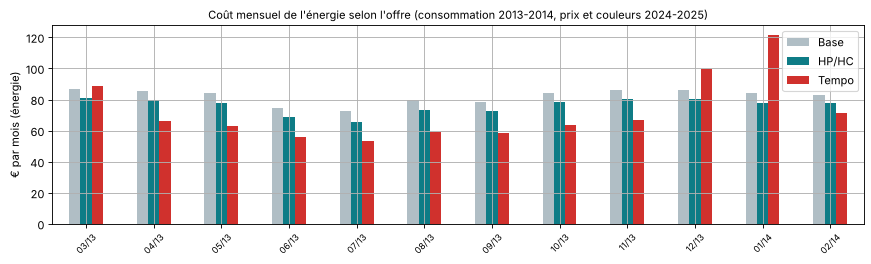

jours Tempo couverts : 365 sur 365 | offre conseillée : Tempo


,énergie (€/an),abonnement (€/an),total (€/an),avec lessive et vaisselle à 22 h (€/an),gain du décalage (€/an),écart vs Base (€/an)
offre,,,,,,
Base,985.0,190.0,1176.0,1176.0,0.0,0.0
HP/HC,914.0,190.0,1104.0,1089.0,15.0,-87.0
Tempo,868.0,190.0,1058.0,1038.0,20.0,-138.0


In [8]:
_SSL = ssl.create_default_context()
try:
    import certifi; _SSL = ssl.create_default_context(cafile=certifi.where())
except ImportError:
    pass

def charger_tempo(saison):
    s = charger_tempo_fichier(saison)
    if s is not None: return s
    try:
        req = urllib.request.Request(f"https://www.api-couleur-tempo.fr/api/joursTempo?periode={saison}", headers={"User-Agent": "projet-M1-ESET-nilm"})
        with urllib.request.urlopen(req, timeout=40, context=_SSL) as r:
            js = json.loads(r.read().decode("utf-8"))
        js = next((v for v in js.values() if isinstance(v, list)), [js]) if isinstance(js, dict) else js
        code = {1: "BLEU", 2: "BLANC", 3: "ROUGE"}
        s = pd.Series({pd.Timestamp(str(it["dateJour"])[:10]): code[int(it["codeJour"])] for it in js if int(it.get("codeJour", 0)) in code})
        s.rename("couleur").rename_axis("date").to_frame().to_csv(PRIX_DIR / f"tempo_{saison}.csv")
        return s
    except Exception as e:
        print(f"Tempo {saison} : téléchargement impossible ({type(e).__name__}) -> jours supposés bleus")
        return None

tempo_an = pd.concat([s for s in (charger_tempo("2023-2024"), charger_tempo("2024-2025")) if s is not None]).sort_index()
OFF_AN = 4018                                         # 1er mars 2013 (vendredi) -> 1er mars 2024 (vendredi)
an = msg_nilm[["total"]].copy()
an["kwh"] = an["total"] / 1000
an = an.groupby(an.index.floor("1h"))["kwh"].sum(min_count=3)
an = an.groupby([an.index.month, an.index.hour]).transform(lambda x: x.fillna(x.mean())).fillna(0)   # trous : moyenne du mois à la même heure
ce = np.zeros(24); ce[22], ce[23], ce[0] = 2.0, 2.0, CHAUFFE_EAU_KWH - 4.0
ce *= CHAUFFE_EAU_KWH / 5.0 if CHAUFFE_EAU_KWH else 0
conso = an.values + ce[an.index.hour]
dates_fr = an.index + pd.Timedelta(days=OFF_AN)

def prix_horaire(offre, t):
    h = t.hour
    if offre == "Base": return BASE
    if offre == "HP/HC": return HPHC["HC"] if h in HC_HOURS else HPHC["HP"]
    j = t.normalize() - (pd.Timedelta(days=1) if h < 6 else pd.Timedelta(0))
    c = tempo_an.get(j, "BLEU")
    return TEMPO[c][0] if (h < 6 or h >= 22) else TEMPO[c][1]

PRIX_AN = {o: np.array([prix_horaire(o, t) for t in dates_fr]) for o in ABONNEMENT}
fact = 365 / (len(conso) / 24)
# gain du décalage des cycles détectés (NILM) au départ conseillé de 22 h, le même jour
prix_s = {o: pd.Series(PRIX_AN[o], index=an.index) for o in ABONNEMENT}
def gain_decalage(offre, appareils=("washing_machine", "dishwasher")):
    g = 0.0
    for a in appareils:
        for _, c in CYC["NILM"][a].iterrows():
            q_ = msg_nilm[a].loc[c["debut"]: c["debut"] + pd.Timedelta(minutes=c["duree_min"] - 15)].fillna(0) / 1000
            nouveau = c["debut"].normalize() + pd.Timedelta(hours=HEURE_CONSEIL)
            p_old = prix_s[offre].reindex(q_.index.floor("1h"), method="nearest").values
            p_new = prix_s[offre].reindex((nouveau + (q_.index - c["debut"])).floor("1h"), method="nearest").values
            g += float((q_.values * (p_old - p_new)).sum())
    return g * fact
offres = []
for o in ABONNEMENT:
    energie = float((conso * PRIX_AN[o]).sum()) * fact
    gd = gain_decalage(o)
    offres.append({"offre": o, "énergie (€/an)": energie, "abonnement (€/an)": ABONNEMENT[o], "total (€/an)": energie + ABONNEMENT[o],
                   "avec lessive et vaisselle à 22 h (€/an)": energie + ABONNEMENT[o] - gd, "gain du décalage (€/an)": gd})
offres = pd.DataFrame(offres).set_index("offre")
offres["écart vs Base (€/an)"] = offres["avec lessive et vaisselle à 22 h (€/an)"] - offres.loc["Base", "total (€/an)"]
OFFRE_CONSEILLEE = offres["avec lessive et vaisselle à 22 h (€/an)"].idxmin()
mensuel = pd.DataFrame({o: pd.Series(conso * PRIX_AN[o], index=an.index).groupby(an.index.to_period("M")).sum() for o in ABONNEMENT})
ax = mensuel.plot.bar(figsize=(11, 3.4), color=["#B0BEC5", "#0E7C86", "#D0312D"], rot=45)
ax.set_xticklabels([p.strftime("%m/%y") for p in mensuel.index], fontsize=8); ax.set_ylabel("€ par mois (énergie)")
ax.set_title("Coût mensuel de l'énergie selon l'offre (consommation 2013-2014, prix et couleurs 2024-2025)", fontsize=10)
plt.tight_layout(); plt.savefig(OUT_DIR / "offres_mensuel.png", dpi=130); plt.show()
print(f"jours Tempo couverts : {tempo_an.reindex(pd.date_range(dates_fr[0].normalize(), dates_fr[-1].normalize())).notna().sum()} "
      f"sur {(dates_fr[-1] - dates_fr[0]).days + 1} | offre conseillée : {OFFRE_CONSEILLEE}")
offres.round(0)

### 7b. Veille, frigo et journées anormales
- **Veille** : le talon calculé en section 3, converti en kWh et en euros par an, et ce que rapporteraient 10 W de veille en moins.
- **Frigo** : je suis son énergie par jour (estimée par le NILM) et je la compare à sa propre référence (médiane des 28 jours précédents). Plusieurs jours de suite à plus de 30 % au-dessus de la référence déclenchent une alerte : porte mal fermée, givre, joint usé, ou appareil qui vieillit. La consommation d'un frigo augmente aussi naturellement en été : l'alerte compare donc à ses semaines récentes, pas à une valeur fixe.
- **Journées anormales** : une journée dont la consommation dépasse de plus de 3 écarts-types la moyenne de son profil d'usage est signalée (oubli d'un appareil allumé, invités, panne…).

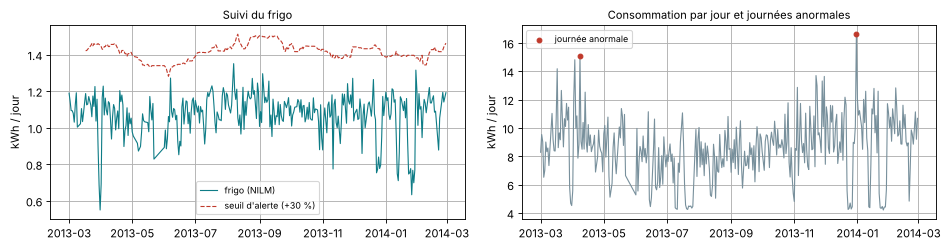

veille : 159 W = 1390 kWh/an = 278 €/an ; 10 W de moins = 18 €/an
alertes frigo : 0 jours | journées anormales : 2 (2013-04-08, 2013-12-31)


In [9]:
frigo = journalier["fridge"]
ref_fr = frigo.rolling(28, min_periods=14).median().shift(1)
ratio = frigo / ref_fr
hausse = (ratio > 1.3).astype(int)
suite = hausse.groupby((hausse != hausse.shift()).cumsum()).transform("sum") * hausse
alertes_frigo = ratio[suite >= 3]
tot_j = H.sum(axis=1); moy_p = tot_j.groupby(LAB).transform("mean"); std_p = tot_j.groupby(LAB).transform("std")
anormaux = tot_j[(tot_j - moy_p) > 3 * std_p]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].plot(frigo.index, frigo.values, color="#0E7C86", lw=1, label="frigo (NILM)")
axes[0].plot(ref_fr.index, ref_fr.values * 1.3, color="#C0392B", ls="--", lw=1, label="seuil d'alerte (+30 %)")
axes[0].scatter(alertes_frigo.index, frigo.reindex(alertes_frigo.index), color="#C0392B", s=12, zorder=3)
axes[0].set_ylabel("kWh / jour"); axes[0].set_title("Suivi du frigo", fontsize=10); axes[0].legend(fontsize=8)
axes[1].plot(tot_j.index, tot_j.values, color="#78909C", lw=1)
axes[1].scatter(anormaux.index, anormaux.values, color="#C0392B", s=18, zorder=3, label="journée anormale")
axes[1].set_ylabel("kWh / jour"); axes[1].set_title("Consommation par jour et journées anormales", fontsize=10); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "alertes.png", dpi=130); plt.show()
print(f"veille : {TALON_W:.0f} W = {TALON_W * 8.76:.0f} kWh/an = {TALON_W * 8.76 * BASE:.0f} €/an ; 10 W de moins = {10 * 8.76 * BASE:.0f} €/an")
print(f"alertes frigo : {alertes_frigo.index.normalize().nunique()} jours | journées anormales : {len(anormaux)} "
      f"({', '.join(str(d.date()) for d in anormaux.index[:6])}{'…' if len(anormaux) > 6 else ''})")

### 7c. Le rapport envoyé au foyer
Le serveur rassemble tout en quelques messages courts, triés par intérêt financier, qu'il peut publier dans Home Assistant (notification sur l'application Companion, carte du tableau de bord) une fois par semaine ou par mois. Le fichier `profils_s9/recommandations.json` contient les mêmes informations sous une forme lisible par Home Assistant (type, titre, texte, gain estimé en €/an).

In [10]:
reco = []
reco.append({"type": "offre", "titre": f"Offre conseillée : {OFFRE_CONSEILLEE}",
             "texte": f"Avec votre profil, l'offre {OFFRE_CONSEILLEE} coûterait {offres.loc[OFFRE_CONSEILLEE, 'avec lessive et vaisselle à 22 h (€/an)']:.0f} €/an "
                      f"(lessive et vaisselle lancées à 22 h), contre {offres.loc['Base', 'total (€/an)']:.0f} €/an en Base.",
             "gain_eur_an": float(-offres.loc[OFFRE_CONSEILLEE, "écart vs Base (€/an)"])})
for nom_a, a in (("lave-linge", "washing_machine"), ("lave-vaisselle", "dishwasher")):
    h_ = habitudes.loc[nom_a]
    g_ = gain_decalage(OFFRE_CONSEILLEE, (a,))
    reco.append({"type": "decalage", "titre": f"Lancer le {nom_a} à {HEURE_CONSEIL} h",
                 "texte": f"Vous lancez le {nom_a} {h_['cycles par semaine']:.1f} fois par semaine, le plus souvent vers {int(h_['heure de départ la plus fréquente'])} h "
                          f"({h_['part des départs en heures pleines (%)']:.0f} % des cycles en heures pleines). Avec un départ différé à {HEURE_CONSEIL} h : "
                          f"environ {g_:.0f} €/an d'économie en {OFFRE_CONSEILLEE}.", "gain_eur_an": g_})
reco.append({"type": "veille", "titre": f"Veille : {TALON_W:.0f} W en permanence",
             "texte": f"Vos appareils en veille consomment environ {TALON_W * 8.76:.0f} kWh par an, soit {TALON_W * 8.76 * BASE:.0f} €. "
                      f"Chaque tranche de 10 W en moins fait gagner {10 * 8.76 * BASE:.0f} €/an (multiprise à interrupteur, box en veille la nuit).",
             "gain_eur_an": 10 * 8.76 * BASE})
if len(alertes_frigo):
    reco.append({"type": "alerte", "titre": "Frigo : consommation en hausse",
                 "texte": f"Le frigo a consommé plus de 30 % au-dessus de son habitude pendant {alertes_frigo.index.normalize().nunique()} jours "
                          f"(dernier : {alertes_frigo.index.max().date()}). Vérifier la porte, le joint et le givre.", "gain_eur_an": 0.0})
if len(anormaux):
    reco.append({"type": "alerte", "titre": f"{len(anormaux)} journées inhabituelles",
                 "texte": "Consommation très au-dessus de votre profil habituel les " + ", ".join(str(d.date()) for d in anormaux.index[-3:]) + ".",
                 "gain_eur_an": 0.0})
reco = sorted(reco, key=lambda r: -r["gain_eur_an"])
(OUT_DIR / "recommandations.json").write_text(json.dumps(reco, ensure_ascii=False, indent=1), encoding="utf-8")
for r in reco:
    print(f"• {r['titre']}\n  {r['texte']}\n")

• Offre conseillée : Tempo
  Avec votre profil, l'offre Tempo coûterait 1038 €/an (lessive et vaisselle lancées à 22 h), contre 1176 €/an en Base.

• Veille : 159 W en permanence
  Vos appareils en veille consomment environ 1390 kWh par an, soit 278 €. Chaque tranche de 10 W en moins fait gagner 18 €/an (multiprise à interrupteur, box en veille la nuit).

• Lancer le lave-linge à 22 h
  Vous lancez le lave-linge 5.2 fois par semaine, le plus souvent vers 14 h (99 % des cycles en heures pleines). Avec un départ différé à 22 h : environ 17 €/an d'économie en Tempo.

• Lancer le lave-vaisselle à 22 h
  Vous lancez le lave-vaisselle 2.4 fois par semaine, le plus souvent vers 22 h (57 % des cycles en heures pleines). Avec un départ différé à 22 h : environ 3 €/an d'économie en Tempo.

• 2 journées inhabituelles
  Consommation très au-dessus de votre profil habituel les 2013-04-08, 2013-12-31.



## 8. Où et comment cette IA tourne côté serveur
- **Entrée** : l'historique des messages de 15 minutes (`maison/nilm_01/q`) que Home Assistant enregistre déjà (base de données de l'historique), soit 96 messages par jour et quelques Mo par an.
- **Fréquence** : les profils et les recommandations sont recalculés une fois par semaine (quelques secondes de calcul) ; la prévision de demain est recalculée chaque après-midi, juste avant le planificateur de la semaine 8.
- **Sorties** : la prévision de consommation pour le planificateur, des capteurs Home Assistant (consommation de veille, profil du jour, cycles par semaine) et les notifications de la section 7c.
- **Outils** : `numpy`, `pandas` et `scipy` uniquement (pas de bibliothèque d'apprentissage lourde) ; le k-means et la détection de cycles tiennent en quelques dizaines de lignes, ce qui permet de les faire tourner sur un petit serveur local : un PC, une box ou un NAS comme le suggère Éric.
- **Données personnelles** : les profils révèlent les habitudes du foyer (heures de présence, de lessive…). Si le serveur est à la maison (NAS, PC, box), ces données ne quittent jamais le domicile ; sur un cloud, il faut un hébergement en France et le consentement du foyer (RGPD).

## 9. Synthèse automatique
Les chiffres clés de l'exécution, enregistrés dans `profils_s9/synthese.txt` pour la rédaction de l'analyse.

In [11]:
ECYC = "énergie d'un cycle (kWh)"
lignes = [f"Messages : {len(msg_nilm)} quarts d'heure, {len(journalier)} jours ; test à partir du {DEBUT_TEST.date()}",
          "Qualité NILM sur le test (erreur d'énergie %) : " + ", ".join(f"{i} {v:+.1f}" for i, v in qualite["erreur énergie (%)"].items()),
          "Identité : " + " ; ".join(f"{k} = {v:.1f}" for k, v in identite.items()),
          "Habitudes : " + " | ".join(f"{i} : {r['cycles par semaine']:.1f}/sem, {r[ECYC]:.2f} kWh, départ {int(r['heure de départ la plus fréquente'])} h, "
                                      f"{r['part des départs en heures pleines (%)']:.0f} % en HP, test NILM {r['cycles/semaine en test (NILM)']:.1f} vs réel {r['cycles/semaine en test (réel)']:.1f}/sem, "
                                      f"heure moy. NILM {r['heure moyenne de départ en test (NILM)']:.1f} vs réel {r['heure moyenne de départ en test (réel)']:.1f}"
                                      for i, r in habitudes.iterrows()),
          "Silhouette : " + str({k: round(v, 3) for k, v in scores.items()}) + f" -> K = {K}",
          "Profils :\n" + profils.round(1).to_string(),
          "Prévision :\n" + eval_prev.round(3).to_string(),
          "Planificateur :\n" + (plan_prev.round(2).to_string() if len(plan_prev) else "non calculé"),
          "Offres :\n" + offres.round(0).to_string(),
          f"Veille {TALON_W:.0f} W ; alertes frigo {alertes_frigo.index.normalize().nunique()} jours ; journées anormales {len(anormaux)}",
          "Recommandations :\n" + "\n".join(f"- {r['titre']} : {r['texte']}" for r in reco)]
(OUT_DIR / "synthese.txt").write_text("\n".join(lignes), encoding="utf-8")
print("\n".join(lignes))

Messages : 35040 quarts d'heure, 334 jours ; test à partir du 2013-11-12
Qualité NILM sur le test (erreur d'énergie %) : frigo +16.3, bouilloire +25.0, lave-linge +1.2, lave-vaisselle +14.6
Identité : jours analysés = 334.0 ; consommation moyenne (kWh/jour) = 8.3 ; en semaine (kWh/jour) = 8.3 ; le week-end (kWh/jour) = 8.4 ; consommation de veille (W) = 158.7 ; veille sur un an (kWh) = 1390.0 ; veille sur un an (€, tarif Base) = 278.1 ; part de la veille dans la consommation (%) = 45.7 ; part du frigo (%) = 12.9 ; part de la bouilloire (%) = 5.4 ; part du lave-linge (%) = 7.3 ; part du lave-vaisselle (%) = 4.8 ; part des autres usages (%) = 69.7
Habitudes : lave-linge : 5.2/sem, 0.76 kWh, départ 14 h, 99 % en HP, test NILM 5.4 vs réel 5.1/sem, heure moy. NILM 14.2 vs réel 14.0 | lave-vaisselle : 2.4/sem, 1.13 kWh, départ 22 h, 57 % en HP, test NILM 2.6 vs réel 2.2/sem, heure moy. NILM 17.3 vs réel 17.0 | bouilloire : 29.4/sem, 0.10 kWh, départ 8 h, 99 % en HP, test NILM 29.2 vs réel 25